<a href="https://colab.research.google.com/github/ShivaL52/FGCT6020-AI-Food-Image-Generator/blob/main/03_image_selection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, torch, pandas as pd
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

BASE = "/content/drive/MyDrive/FGCT6020_Project for AI for Creativity/02_dataset"
folder = f"{BASE}/raw_train"
files = sorted(os.listdir(folder))

# The sentence CLIP compares every image with
text = ["a professional, appetising food photograph of chicken curry"]

scores = []
with torch.no_grad():
    for f in files:
        img = Image.open(f"{folder}/{f}").convert("RGB")
        inputs = processor(text=text, images=img, return_tensors="pt", padding=True).to(device)
        out = model(**inputs)

        # Image and text vectors from the model's main output
        v = out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)
        t = out.text_embeds / out.text_embeds.norm(dim=-1, keepdim=True)

        scores.append((f, (v @ t.T).item(), img.size[0], img.size[1]))

df = pd.DataFrame(scores, columns=["file", "clip_score", "width", "height"])
df = df.sort_values("clip_score", ascending=False).reset_index(drop=True)
df.to_csv(f"{BASE}/clip_scores_train.csv", index=False)

print("Images scored:", len(df))
print(df.head(5))
print(df.tail(5))


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Images scored: 750
          file  clip_score  width  height
0  1442176.jpg    0.343261    512     384
1   404391.jpg    0.341130    384     512
2   752379.jpg    0.337662    512     384
3   474188.jpg    0.334581    512     512
4  2930745.jpg    0.334141    512     512
            file  clip_score  width  height
745   171055.jpg    0.216672    382     512
746   668711.jpg    0.215644    382     512
747  2523126.jpg    0.170293    512     377
748  1753210.jpg    0.169074    383     512
749   789540.jpg    0.141056    341     512


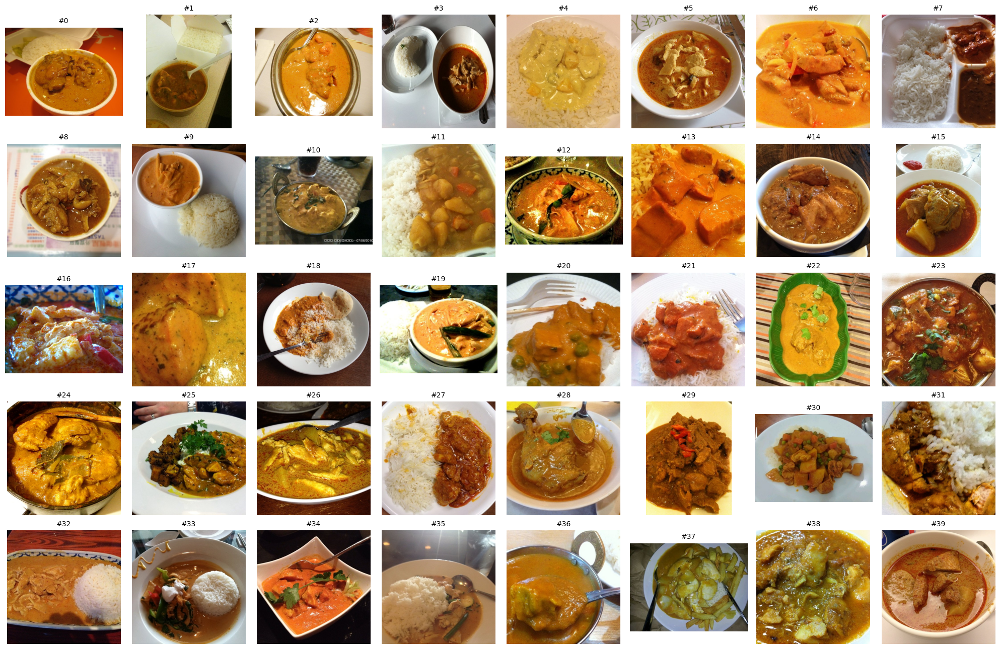

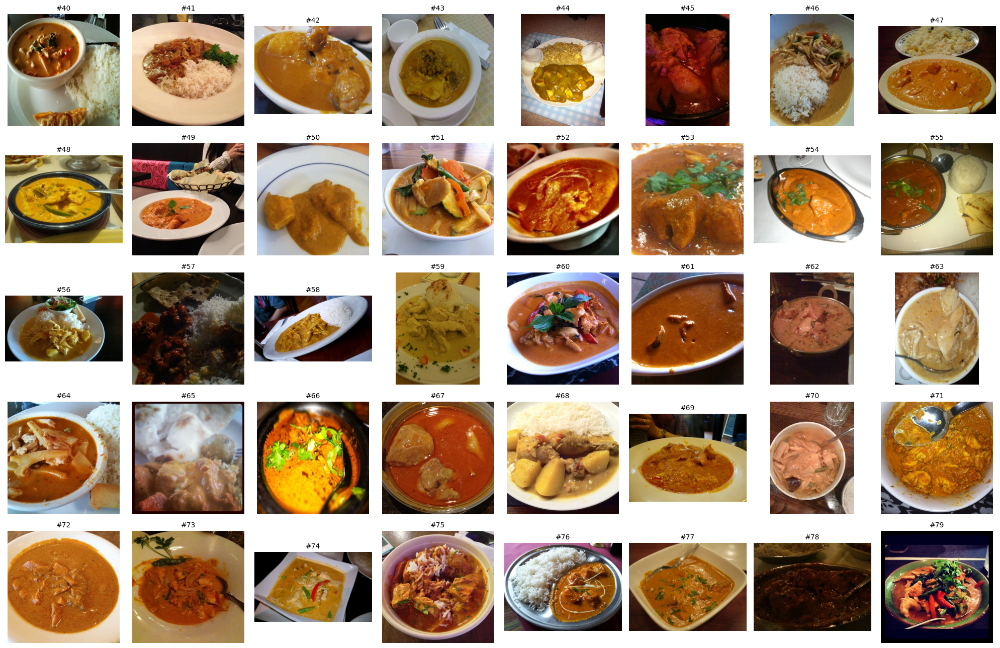

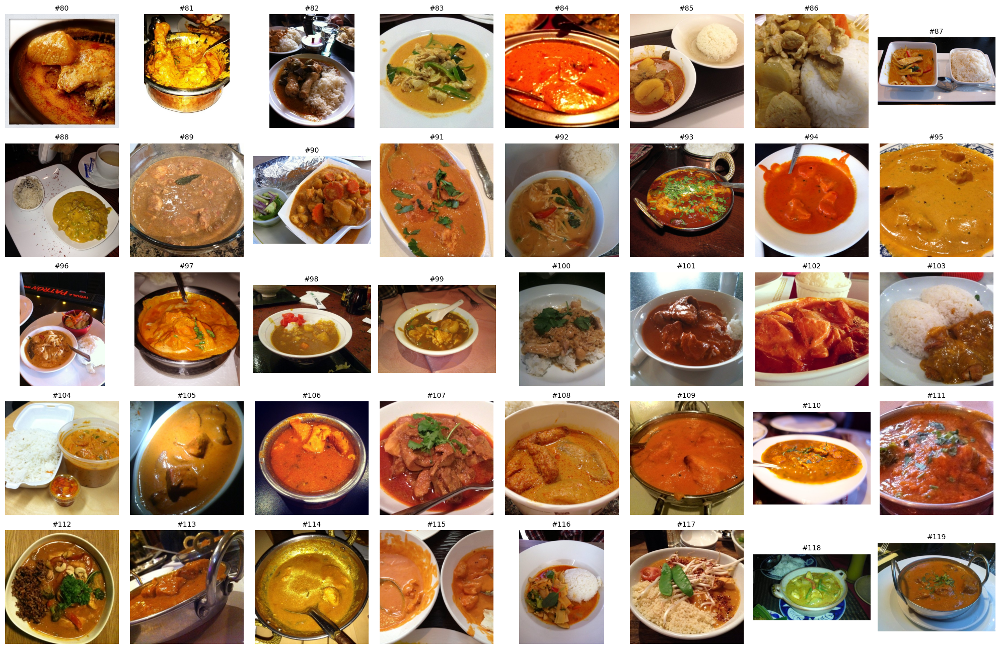

In [ ]:
import matplotlib.pyplot as plt

top = df.head(120)
for start in range(0, 120, 40):
    fig, axes = plt.subplots(5, 8, figsize=(20, 13))
    for i, ax in enumerate(axes.flat):
        k = start + i
        ax.imshow(Image.open(f"{folder}/{top.file[k]}"))
        ax.set_title(f"#{k}", fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

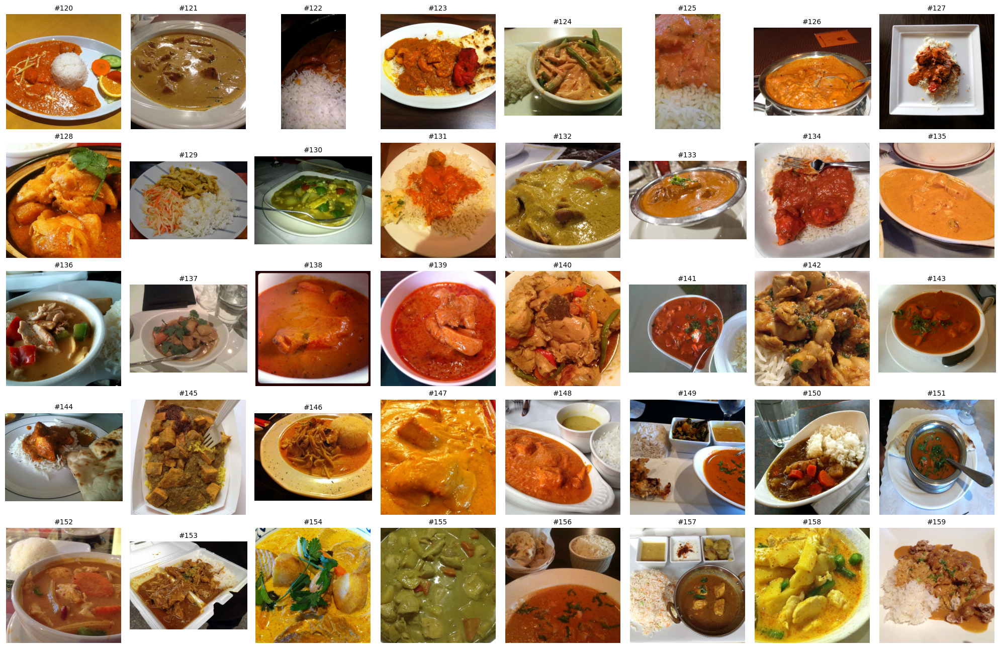

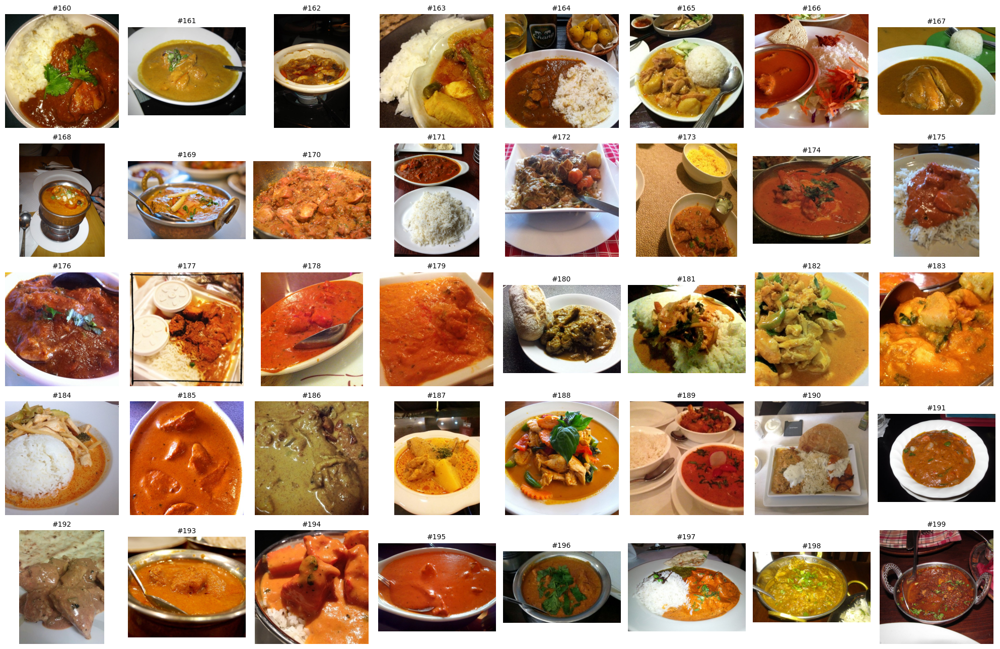

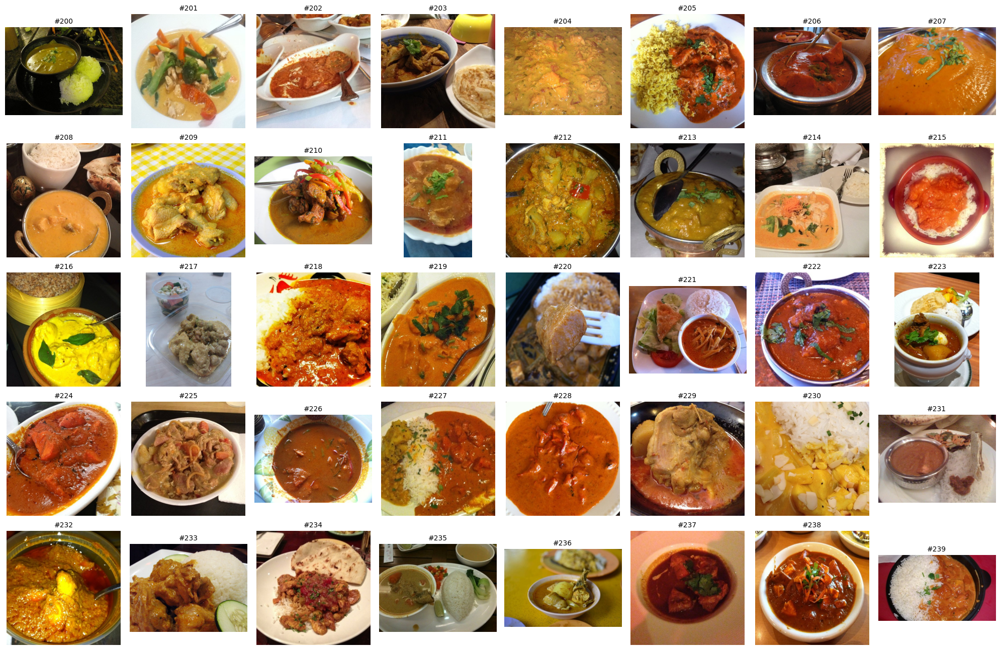

In [ ]:
nxt = df.iloc[120:240]
for start in range(120, 240, 40):
    fig, axes = plt.subplots(5, 8, figsize=(20, 13))
    for i, ax in enumerate(axes.flat):
        k = start + i
        ax.imshow(Image.open(f"{folder}/{nxt.file[k]}"))
        ax.set_title(f"#{k}", fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


In [3]:
import os, shutil, pandas as pd

BASE = "/content/drive/MyDrive/FGCT6020_Project for AI for Creativity/02_dataset"
folder = f"{BASE}/raw_train"
df = pd.read_csv(f"{BASE}/clip_scores_train.csv")   # the saved CLIP ranking

# B = blurry, D = dark/flash, N = curry not clearly visible, P = people/text,
# S = not chicken / not South Asian chicken curry, X = duplicate,
# A = not restaurant-advertising style, O = other quality/presentation problem
rejects = {
    "S": [0, 5, 6, 8, 9,            # checked 9 is not chieken
          11, 13, 16, 17, 18, 19, 20, 21, 22, 26, 42,46,
          107,            # ? checked 108, 109 this is not clear so i kept in the N section
          112, 116, 117,
          123, 124,234,136,            #
          145],                     # lamb
    "A": [1, 3, 4, 76, 120, 122, 125, 27, 35,128],
    "B": [78, 93, 106, 110, 111],
    "N": [114, 115, 118, 119, 121, 126, 108, 109, 134, 202],
    "D": [],
    "P": [],
    "X": [],
    "O": [ 30, 31, 32, 33, 36, 37, 40, 41, 43,      # ? check 27, 35, 42, 43 checked
          44, 47, 48, 49, 50, 52, 54, 55, 56, 57,           # ? check 44, 46 and moved 46 to S
          58, 59, 60, 62, 64, 65, 66, 68, 69, 70, 72, 73,       # ? check 58 ic checked it goes to O because curry is not presentes like that
          75, 79, 80, 83, 84, 85, 86, 87, 88, 90, 91, 92, 94,
          96, 98, 99, 100, 102, 103, 104,
          129, 130, 131, 137, 139, 142, 144,          # ? check 134, 136 both checked and moved to respective folder
          146, 148, 149, 150, 151, 152, 153,
          155, 156, 157, 158, 160, 163, 164, 165, 166,
          171, 172, 173, 175, 177, 180, 181, 182,
          183, 187, 188, 189, 190, 191, 192, 194,
          197, 200, 201,203, 205,                         # ? check 202 checked and moved to respective folder
          214, 215, 216, 217, 218, 220, 221, 223,
          227, 230, 233,235, 239],                        # ? check 234, 235 hecked and moved to respective folder
}

reviewed = df.head(240).copy()          # ranks #0 – #239
reviewed["rank"] = range(240)
reviewed["decision"] = "keep"
reviewed["reason"] = ""

for code, nums in rejects.items():
    for n in nums:
        if n < 0 or n > 239:
            print("Check this number, it is outside 0–239:", n)
            continue
        reviewed.loc[n, "decision"] = "reject"
        reviewed.loc[n, "reason"] = code

out = f"{BASE}/selected_train"
os.makedirs(out, exist_ok=True)
kept = reviewed[reviewed.decision == "keep"]
for f in kept.file:
    shutil.copy(f"{folder}/{f}", f"{out}/{f}")

reviewed.to_csv(f"{BASE}/selection_log.csv", index=False)

print("Reviewed:", len(reviewed))
print("Kept:", len(kept))
print("Rejected:", (reviewed.decision == "reject").sum())
print(reviewed[reviewed.decision == "reject"].reason.value_counts())

Reviewed: 240
Kept: 81
Rejected: 159
reason
O    108
S     26
A     10
N     10
B      5
Name: count, dtype: int64


Images in selected_train: 73


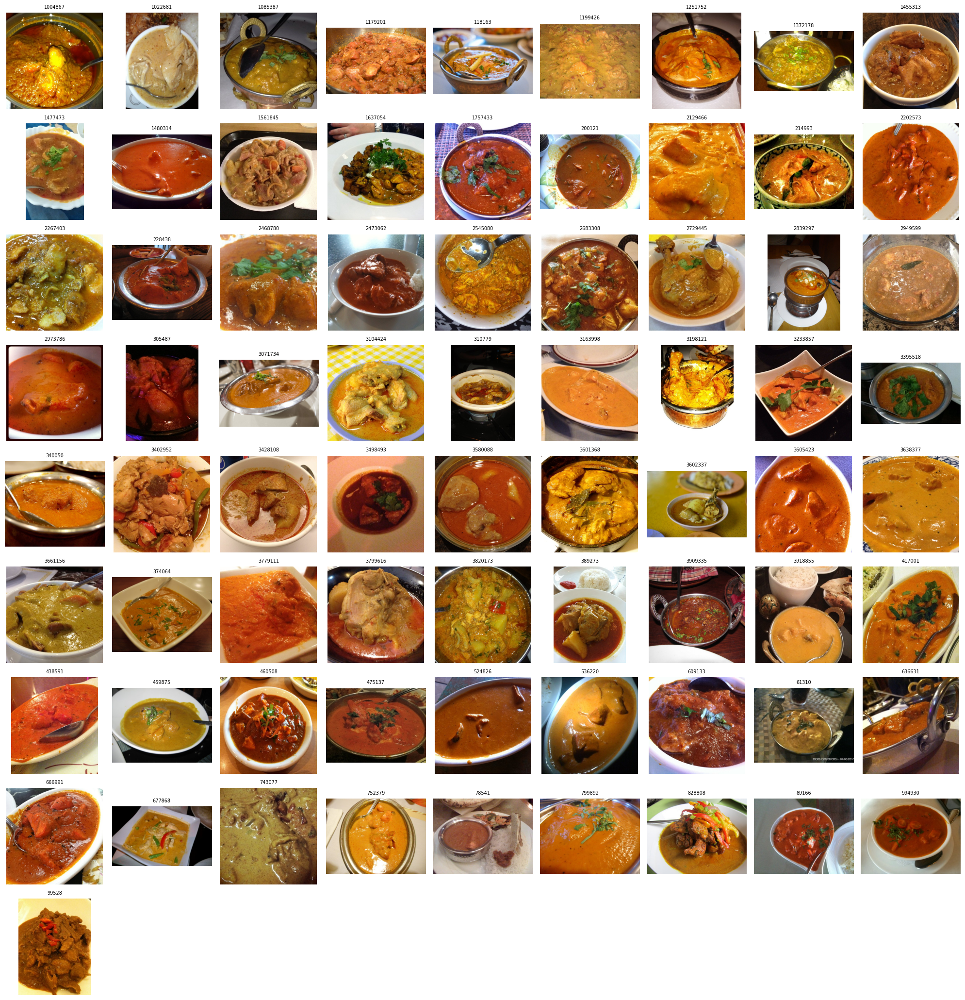

In [9]:
import matplotlib.pyplot as plt
from PIL import Image

sel = sorted(os.listdir(out))
print("Images in selected_train:", len(sel))

cols = 9
rows = (len(sel) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(20, 2.3 * rows))
for i, ax in enumerate(axes.flat):
    ax.axis("off")
    if i < len(sel):
        ax.imshow(Image.open(f"{out}/{sel[i]}"))
        ax.set_title(sel[i][:-4], fontsize=7)   # file name, so you can find it
plt.tight_layout()
plt.savefig(f"{BASE}/selected_train_overview.png", dpi=100)   # saved as evidence
plt.show()

In [7]:
# Second review pass: file names (WITHOUT .jpg) to remove from selected_train
second_pass = {
    "A": ["1560953", "2044445", "3500420", "280714", "217926"],
    "S": ["2123860", "1782739", "2342516"],
    "B": [],
    "N": [],
    "O": [],
}

log = pd.read_csv(f"{BASE}/selection_log.csv")
if "review_pass" not in log.columns:
    log["review_pass"] = 1

for code, names in second_pass.items():
    for name in names:
        f = f"{name}.jpg"
        if f not in log.file.values:
            print("Not found, check the name:", name)
            continue
        log.loc[log.file == f, ["decision", "reason", "review_pass"]] = ["reject", code, 2]
        p = f"{out}/{f}"
        if os.path.exists(p):
            os.remove(p)      # removes only the COPY in selected_train; raw_train is safe

log.to_csv(f"{BASE}/selection_log.csv", index=False)
print("Images now in selected_train:", len(os.listdir(out)))
print(log.decision.value_counts())


Images now in selected_train: 73
decision
reject    167
keep       73
Name: count, dtype: int64
